# Module 3 — Timeline & Events-and-Causal-Factors Reconstruction

Part of the Root-Cause Analysis Playbook. Program and progress: [CURRICULUM.md](CURRICULUM.md).

## Why you're here: what this module is for

- Before asking *why* an incident happened, you need the facts: what happened, when, in what order, and how sure you are of each.
- In DMAIC (Define, Measure, Analyze, Improve, Control), this is a **Measure** tool: it builds the fact base the Analyze phase works from.
- The timeline also shows *where the time went*, which often matters as much as what broke.

**What this module produces:**
1. A timeline of a real incident, each event with its time, its source and how sure we are of it.
2. The incident's four standard durations: time to detect, to diagnose, to mitigate and to recover fully.
3. An events-and-causal-factors (E&CF) chart: the events, the conditions behind them, and which conditions were causal factors.

## From the curriculum

> ## <u>Module 3 — Timeline & Events-and-Causal-Factors Reconstruction</u>
>
> **DMAIC phase:** Measure (establishing the facts and their order before
> asking why).
>
> **Concepts**
> - The timeline as the first fact base of an incident: every event with its
>   time, its source, and how sure we are of it (stated, derived, recalled, or
>   no time)
> - The key durations: time to detect, time to diagnose, time to mitigate,
>   time to recover fully
> - Events-and-causal-factors (E&CF) charting: the chain of events in time
>   order, the conditions that made each event possible, and the causal
>   factors: the events or conditions without which the outcome would not have
>   happened, or would have been much smaller
> - Conditions often predate the incident window by weeks; a timeline that
>   starts at the first alert misses them
> - Ordering pitfalls: the order a report tells events in is not the order
>   they happened; "after" is not "because"; an "event" can be a phase, not a
>   single moment
>
> **Why it matters**
> Arguments about causes often turn out to be arguments about order. A timeline
> built from timestamped evidence settles the order, and the durations show
> where the time was really lost, before anyone argues about causes.
>
> **Worked example**
> Fresh and real: Cloudflare's published postmortem of its 2 July 2019 global
> outage (a firewall rule with a runaway regular expression took down most of
> its traffic for 27 minutes). Chosen because it publishes exact timestamps and
> an honest list of contributing conditions:
> - The timeline is rebuilt from the post's own timestamps, and it reproduces
>   the post's 27 minutes (13:42 deploy to 14:09 recovery).
> - The four standard durations show where the time went: 3 minutes to
>   detect, 15 to diagnose, 9 to mitigate, 70 to recover fully.
> - The E&CF chart links each event to the conditions behind it, including a
>   CPU protection removed weeks before the incident.
>
> Sidenote: the E12 NYC 311 investigation (an earlier exercise) dated a label
> change to 29 July, but an independent check found it was phased from 1 June: an event
> that was really a phase.
>
> **Resources**
> - [Details of the Cloudflare outage on July 2, 2019](https://blog.cloudflare.com/details-of-the-cloudflare-outage-on-july-2-2019/)
>   (Cloudflare Blog, 2019, ~25 min, verified): the source of this module's
>   worked example.
> - [DOE-STD-1197-2024, Causal Analysis](https://www.energy.gov/documents/doe-std-1197-2024-finalpdf)
>   (U.S. Department of Energy, 2024, PDF, ~15 min for the E&CF charting
>   section, verified): how E&CF charts show the conditions and events needed
>   for an incident.
>
> **Exercise type:** mark how sure each number in the postmortem is (stated,
> derived, recalled, or no time). Fully worked.
>
> **Interview angle:** "Tell me about an incident you investigated: what
> happened, in what order?"

## Lesson

### The timeline: one row per event

Each row has four parts:
- **Time:** when it happened, in one time zone (here UTC, Coordinated Universal Time).
- **Event:** what happened, in one short sentence.
- **Source:** where the fact comes from (a log, a ticket, a written account).
- **How sure:** one of four labels:
  - *stated*: the source gives the time
  - *derived*: worked out from the source, e.g. "three minutes later"
  - *recalled*: someone remembered or passed it on, with nothing written down
  - *no time*: the source gives no time

### The four standard durations

- **Time to detect:** from the trigger to the first alert.
- **Time to diagnose:** from the first alert to knowing what is wrong.
- **Time to mitigate:** from knowing what is wrong to the damage stopping.
- **Time to recover fully:** from the trigger until everything is back to normal, including anything switched off to stop the damage.

### Events and causal factors (E&CF)

An E&CF chart adds two things to the timeline:
- **Conditions:** states that were true at the time and made an event possible, e.g. "the tests do not check CPU use". Conditions often started long before the incident.
- **Causal factors:** the events or conditions without which the outcome would not have happened, or would have been much smaller. The test: remove it, and ask whether the incident still happens at the same size. That answer is a judgement, so it is a Hypothesis unless it can be tested.

### Three ordering pitfalls

1. **Told order is not time order.** Reports tell the story in the order that is clearest, not the order things happened. Sort by time.
2. **"After" is not "because".** An event right before an incident is a suspect, not a cause, especially when such events are frequent.
3. **Conditions start before the window.** A timeline that starts at the first alert misses what was set up days or weeks earlier.

## Worked example: Cloudflare's global outage, 2 July 2019

**Data choice: fresh (new to this playbook), real.** Cloudflare published a postmortem (a company's own public write-up of an incident) with exact times for every step and an honest list of what went wrong. Most incident write-ups give far less.

**Source:** [Details of the Cloudflare outage on July 2, 2019](https://blog.cloudflare.com/details-of-the-cloudflare-outage-on-july-2-2019/) (Cloudflare Blog). All times are UTC, as in the post. Every event below is transcribed from the post, with a short quote as its source.

**What happened, in one sentence:** a new firewall rule contained a regex (regular expression, a text-matching pattern) that used up the CPU (the processor) of every server handling web traffic, and most of Cloudflare's traffic failed until the firewall was switched off worldwide.

**Terms in the quotes:** WAF = Web Application Firewall (the firewall), Pull Request = a code change submitted for review, TeamCity = the build system that tests and deploys code, PagerDuty = the alerting service that pages engineers, "global terminate" = switching one component off on every server at once.

**Where this was already done, unnamed:** in the user's E12 NYC 311 investigation (an earlier exercise), a label change was first dated to 29 July. An independent check found it was phased: the new labels were in use from 1 June. An event that was really a phase.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import common
from common import show, BLUE, ORANGE, GREY

T = lambda hm: pd.Timestamp(f"2019-07-02 {hm}")
WEEKS_BEFORE = pd.Timestamp("2019-06-01")  # placeholder for "weeks prior": the post gives no date
# Entered in the order the post tells them: it opens with the CPU spike, then the 13:42 deploy,
# and gives 13:31, 13:37 and the removed protection only in later sections.
told = pd.DataFrame([
    {"time": "after 13:42", "sort": T("13:42:30"), "event": "Web-traffic CPUs near 100% on servers worldwide",
     "source": "\"spiking to nearly 100% usage across the servers in our network\"", "how sure": "no time"},
    {"time": "13:42", "sort": T("13:42"), "event": "The rule change deploys automatically to every server worldwide",
     "source": "\"At 13:42 an engineer working on the firewall team deployed a minor change\"", "how sure": "stated"},
    {"time": "13:45", "sort": T("13:45"), "event": "The first alert: a test of the firewall fails",
     "source": "\"Three minutes later the first PagerDuty page went out ... This was a synthetic test\"", "how sure": "derived"},
    {"time": "13:45-14:00", "sort": T("13:50"), "event": "The team suspects an unknown kind of attack",
     "source": "\"In the initial moments of the outage there was speculation it was an attack\"", "how sure": "recalled"},
    {"time": "14:00", "sort": T("14:00"), "event": "The firewall is identified as the cause, an attack is ruled out",
     "source": "\"At 14:00 the WAF was identified as the component causing the problem and an attack dismissed\"", "how sure": "stated"},
    {"time": "14:02", "sort": T("14:02"), "event": "The team proposes switching the firewall off worldwide",
     "source": "\"At 14:02 ... it was proposed that we use a 'global terminate'\"", "how sure": "stated"},
    {"time": "14:07", "sort": T("14:07"), "event": "The firewall is switched off worldwide",
     "source": "\"a team member executed the global WAF termination at 14:07\"", "how sure": "stated"},
    {"time": "14:09", "sort": T("14:09"), "event": "Traffic and CPU are back to normal worldwide",
     "source": "\"by 14:09 traffic levels and CPU were back to expected levels\"", "how sure": "stated"},
    {"time": "14:52", "sort": T("14:52"), "event": "The firewall is switched back on, with the fix in place",
     "source": "\"At 14:52 ... the WAF was re-enabled globally\"", "how sure": "stated"},
    {"time": "13:31", "sort": T("13:31"), "event": "An engineer merges the rule change after it is approved",
     "source": "\"At 13:31 an engineer on the team had merged a Pull Request\"", "how sure": "stated"},
    {"time": "13:37", "sort": T("13:37"), "event": "The build system builds the rules and the tests pass",
     "source": "\"At 13:37 TeamCity built the rules and ran the tests\"", "how sure": "stated"},
    {"time": "weeks before", "sort": WEEKS_BEFORE, "event": "A CPU-use protection is removed by mistake while the firewall code is refactored",
     "source": "\"removed by mistake during a refactoring of the WAF weeks prior\"", "how sure": "no time"},
])
told.insert(0, "told #", range(1, len(told) + 1))
timeline = told.sort_values("sort").drop(columns="sort").reset_index(drop=True)
print("The timeline, sorted by time (UTC). Read it top to bottom.")
print("\"told #\" = the order in which the post mentions each event (1 = mentioned first).")
print("The post opens with the CPU spike and the 13:42 deploy, and mentions the 13:31 merge only 10th:\n")
show(timeline[["time", "told #", "event", "source", "how sure"]])

print("\nHow sure are the times?")
for k, v in timeline["how sure"].value_counts().items():
    print(f"  {k} = {v}")
gap = lambda a, b: int((T(b) - T(a)).total_seconds() // 60)
print("\nHow long before the deploy were the change merged and tested? (minutes)")
print(f"  merge -> deploy = 13:31 -> 13:42 = {gap('13:31', '13:42')}")
print(f"  tests pass -> deploy = 13:37 -> 13:42 = {gap('13:37', '13:42')}")

The timeline, sorted by time (UTC). Read it top to bottom.
"told #" = the order in which the post mentions each event (1 = mentioned first).
The post opens with the CPU spike and the 13:42 deploy, and mentions the 13:31 merge only 10th:

time          told #  event                                                                             source                                                                                          how sure
weeks before      12  A CPU-use protection is removed by mistake while the firewall code is refactored  "removed by mistake during a refactoring of the WAF weeks prior"                                no time
13:31             10  An engineer merges the rule change after it is approved                           "At 13:31 an engineer on the team had merged a Pull Request"                                    stated
13:37             11  The build system builds the rules and the tests pass                              "At 13:37 TeamCity built the rules

**Observation:** the post tells the merge and the tests 10th and 11th, and the removed protection 12th, but in time they come first. Sorted by time, the change was merged 11 minutes and tested 5 minutes before it deployed.

**Observation:** one condition sits weeks outside the incident window: the CPU protection was removed "weeks prior" (shown as "weeks before"; the post gives no date). A timeline that started at the first alert (13:45) would miss it.

**Observation:** 8 of the 12 times are stated in the post. One (13:45) is derived from "three minutes later", one (the attack suspicion) is recalled with only a rough time, and two have no time.

### Part 1 — Where did the time go?

In [2]:
t = {hm: T(hm) for hm in ["13:42", "13:45", "14:00", "14:02", "14:07", "14:09", "14:52"]}
mins = lambda a, b: int((t[b] - t[a]).total_seconds() // 60)
phases = [("detect", "13:42", "13:45"), ("diagnose", "13:45", "14:00"), ("propose the fix", "14:00", "14:02"),
          ("execute the fix", "14:02", "14:07"), ("traffic returns", "14:07", "14:09"), ("restore the firewall", "14:09", "14:52")]
print("How long did each phase take? (minutes)")
for name, a, b in phases:
    print(f"  {name} = {a} -> {b} = {mins(a, b)}")
print()
print("The four standard durations (minutes):")
print(f"  time to detect = 13:42 -> 13:45 = {mins('13:42', '13:45')}")
print(f"  time to diagnose = 13:45 -> 14:00 = {mins('13:45', '14:00')}")
print(f"  time to mitigate = propose + execute + traffic returns = {mins('14:00', '14:02')} + {mins('14:02', '14:07')} + {mins('14:07', '14:09')} = {mins('14:00', '14:09')}")
print(f"  time to recover fully = 13:42 -> 14:52 = {mins('13:42', '14:52')}")
print()
print(f"time to restore service (deploy to traffic back) = 13:42 -> 14:09 = {mins('13:42', '14:09')} (the post also says 27 minutes)")

How long did each phase take? (minutes)
  detect = 13:42 -> 13:45 = 3
  diagnose = 13:45 -> 14:00 = 15
  propose the fix = 14:00 -> 14:02 = 2
  execute the fix = 14:02 -> 14:07 = 5
  traffic returns = 14:07 -> 14:09 = 2
  restore the firewall = 14:09 -> 14:52 = 43

The four standard durations (minutes):
  time to detect = 13:42 -> 13:45 = 3
  time to diagnose = 13:45 -> 14:00 = 15
  time to mitigate = propose + execute + traffic returns = 2 + 5 + 2 = 9
  time to recover fully = 13:42 -> 14:52 = 70

time to restore service (deploy to traffic back) = 13:42 -> 14:09 = 27 (the post also says 27 minutes)


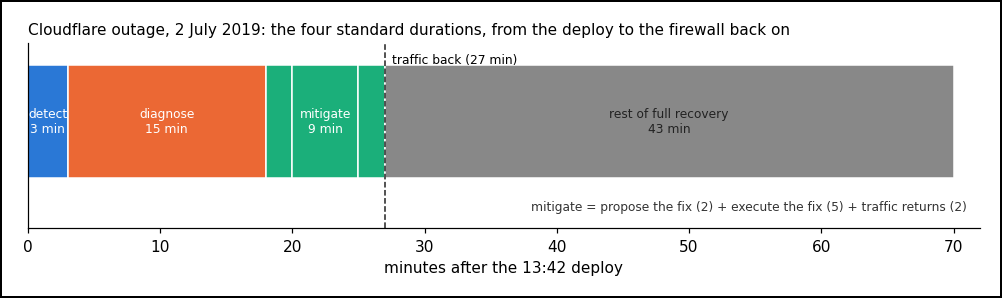

In [3]:
fig, ax = plt.subplots(figsize=(9, 2.6))
AQUA = common.AQUA
duration_of = {"detect": "detect", "diagnose": "diagnose", "propose the fix": "mitigate", "execute the fix": "mitigate",
               "traffic returns": "mitigate", "restore the firewall": "rest of full recovery"}
colors = {"detect": BLUE, "diagnose": ORANGE, "mitigate": AQUA, "rest of full recovery": GREY}
for name, a, b in phases:
    ax.barh(0, mins(a, b), left=mins("13:42", a), color=colors[duration_of[name]], edgecolor="white")
for label, a, b, dark in [("detect", "13:42", "13:45", False), ("diagnose", "13:45", "14:00", False),
                          ("mitigate", "14:00", "14:09", False), ("rest of full recovery", "14:09", "14:52", True)]:
    ax.text(mins("13:42", a) + mins(a, b) / 2, 0, f"{label}\n{mins(a, b)} min", ha="center", va="center", fontsize=8,
            color="#222222" if dark else "white")
ax.axvline(27, color="#222222", lw=1, ls="--")
ax.text(27.5, 0.48, "traffic back (27 min)", fontsize=8, va="top")
ax.set_yticks([]); ax.set_xlim(0, 72); ax.set_ylim(-0.75, 0.55); ax.grid(False)
ax.set_xlabel("minutes after the 13:42 deploy")
ax.set_title("Cloudflare outage, 2 July 2019: the four standard durations, from the deploy to the firewall back on", fontsize=10, loc="left")
ax.text(71, -0.62, "mitigate = propose the fix (2) + execute the fix (5) + traffic returns (2)", ha="right", fontsize=8, color="#333333")
plt.tight_layout(); plt.show()

**Observation:** the timeline reproduces the post's own 27 minutes (13:42 deploy to 14:09 traffic back), a check that the times are consistent.

**Observation:** detection was the shortest of the four standard durations (3 of the 27 minutes). Diagnosis was the longest: 15 minutes from the first alert to knowing it was the firewall. Mitigation took 9, of which 5 were spent executing a fix proposed at 14:02. The post explains the 5: with its own login service down, the team "couldn't authenticate to our internal control panel", and had to use "a bypass mechanism that wasn't frequently used".

**Observation:** full recovery took 70 minutes: the firewall stayed off for 43 more minutes after traffic returned, while the fix was tested.

**Hypothesis:** in a future outage, the most minutes could be saved in diagnosis (15 minutes) and in executing the fix (5), the two longest parts of the 27 minutes customers were down. The 43 minutes after traffic returned are left out because customers were already served again. Detection, at 3, is already the shortest of the four durations.

### Part 2 — Which conditions made it possible? (the E&CF chart)

The post lists what went wrong, under "the multiple vulnerabilities that converged". Each item is a condition: something that was true at the time. Not every condition is a causal factor. To sort them, the table applies the causal-factor test to each one: without it, would the outage have been avoided or much smaller? Yes = causal factor, no = it only made things longer or worse.

In [4]:
conditions = pd.DataFrame([
    ("An engineer wrote a regex that could backtrack (retry) enormously", "the list", "CPUs near 100%", "yes: the rule is the trigger"),
    ("A CPU-use protection was removed weeks before", "the list", "CPUs near 100%", "yes: the regex's CPU use would have been capped"),
    ("The regex engine has no limit on how long a match can run", "the list", "CPUs near 100%", "yes: a bounded engine cannot run away"),
    ("The tests check what a rule blocks, not how much CPU it uses", "the list", "13:37 tests pass", "yes: the tests would have stopped the rule"),
    ("A non-emergency rule change may go to every server at once, no staged rollout", "the list", "13:42 deploys worldwide", "yes, for the size: a staged rollout starts on a few servers"),
    ("A rule in test-only (\"simulate\") mode still runs on real traffic", "the main text", "CPUs near 100%", "yes: the rule was not meant to act, but it still ran"),
    ("The rollback plan needed the full firewall build run twice", "the list", "14:02 the fix chosen", "no: it ruled out a quick rollback, so the team used the global terminate"),
    ("The separate alert for the global traffic drop fired late (no time given)", "the list", "detection", "no: the 13:45 firewall-test alert fired first"),
    ("Internal systems were hard to reach, the bypass was not well trained", "the list", "14:02-14:07 execute the fix", "no: it made the outage longer"),
    ("Some engineers' access had timed out for security reasons", "the list", "14:02-14:07 execute the fix", "no: it made the outage longer"),
    ("The status page was not updated quickly enough", "the list", "customer impact", "no: it made it worse for customers"),
    ("Customers' dashboard and API ran through the failing network", "the list", "customer impact", "no: it made it worse for customers"),
], columns=["condition", "from the post's", "the event it made possible", "causal factor? (without it, avoided or much smaller?)"])
print("Conditions behind the events (12 items: 11 from the post's list of what went wrong, 1 from its main text):\n")
show(conditions)
causal = conditions.iloc[:, 3].str.startswith("yes")
print(f"\ncausal factors = {causal.sum()}")
print(f"made it longer or worse = {(~causal).sum()}")

Conditions behind the events (12 items: 11 from the post's list of what went wrong, 1 from its main text):

condition                                                                      from the post's  the event it made possible   causal factor? (without it, avoided or much smaller?)
An engineer wrote a regex that could backtrack (retry) enormously              the list         CPUs near 100%               yes: the rule is the trigger
A CPU-use protection was removed weeks before                                  the list         CPUs near 100%               yes: the regex's CPU use would have been capped
The regex engine has no limit on how long a match can run                      the list         CPUs near 100%               yes: a bounded engine cannot run away
The tests check what a rule blocks, not how much CPU it uses                   the list         13:37 tests pass             yes: the tests would have stopped the rule
A non-emergency rule change may go to every server at o

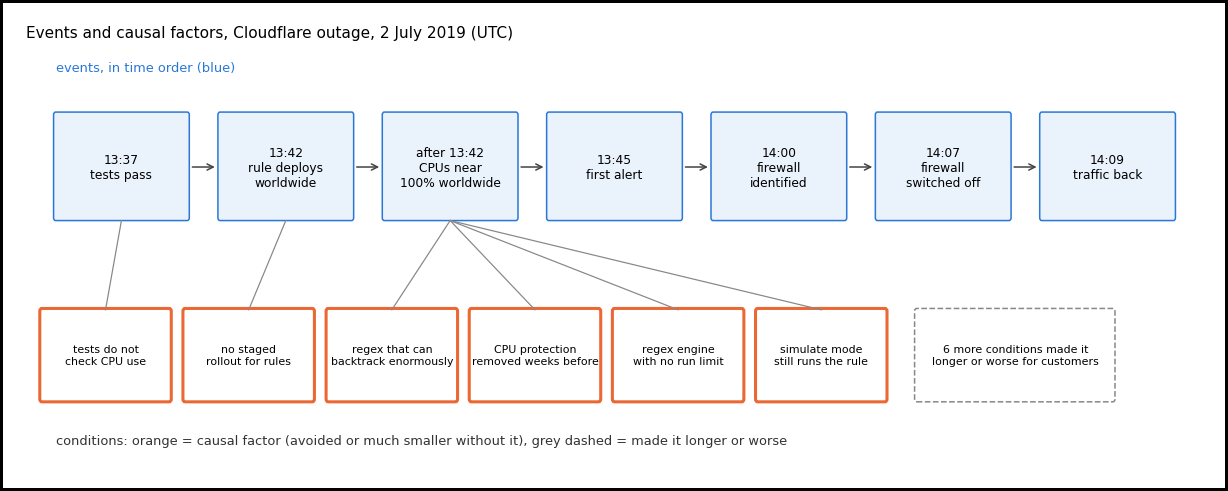

In [5]:
from matplotlib.patches import FancyBboxPatch

events = [("13:37", "tests pass"), ("13:42", "rule deploys\nworldwide"), ("after 13:42", "CPUs near\n100% worldwide"),
          ("13:45", "first alert"), ("14:00", "firewall\nidentified"), ("14:07", "firewall\nswitched off"), ("14:09", "traffic back")]
conds = [(0, "tests do not\ncheck CPU use"), (1, "no staged\nrollout for rules"), (2, "regex that can\nbacktrack enormously"),
         (2, "CPU protection\nremoved weeks before"), (2, "regex engine\nwith no run limit"), (2, "simulate mode\nstill runs the rule")]
fig, ax = plt.subplots(figsize=(11, 4.3))
xs = [i * 1.55 for i in range(len(events))]
for x, (hm, lab) in zip(xs, events):
    ax.add_patch(FancyBboxPatch((x - 0.62, 1.55), 1.24, 0.75, boxstyle="round,pad=0.02", fc="#eaf2fc", ec=BLUE))
    ax.text(x, 1.92, f"{hm}\n{lab}", ha="center", va="center", fontsize=8)
for a, b in zip(xs[:-1], xs[1:]):
    ax.annotate("", xy=(b - 0.64, 1.92), xytext=(a + 0.64, 1.92), arrowprops=dict(arrowstyle="->", color="#444444"))
cond_x = [-0.15, 1.2, 2.55, 3.9, 5.25, 6.6]
for (i, lab), x in zip(conds, cond_x):
    ax.add_patch(FancyBboxPatch((x - 0.6, 0.23), 1.2, 0.64, boxstyle="round,pad=0.02", fc="white", ec=ORANGE, lw=2))
    ax.text(x, 0.55, lab, ha="center", va="center", fontsize=7.2)
    ax.plot([x, xs[i]], [0.88, 1.53], color=GREY, lw=0.8)
ax.add_patch(FancyBboxPatch((xs[5] - 0.25, 0.23), 1.85, 0.64, boxstyle="round,pad=0.02", fc="white", ec=GREY, ls="--"))
ax.text(xs[5] + 0.68, 0.55, "6 more conditions made it\nlonger or worse for customers", ha="center", va="center", fontsize=7.2)
ax.text(xs[0] - 0.62, 2.62, "events, in time order (blue)", fontsize=8.5, color=BLUE)
ax.text(xs[0] - 0.62, -0.1, "conditions: orange = causal factor (avoided or much smaller without it), grey dashed = made it longer or worse",
        fontsize=8.5, color="#333333")
ax.set_xlim(-0.9, xs[-1] + 0.9); ax.set_ylim(-0.25, 2.8); ax.axis("off")
ax.set_title("Events and causal factors, Cloudflare outage, 2 July 2019 (UTC)", fontsize=10, loc="left")
plt.tight_layout(); plt.show()

**Hypothesis (judged from the post's account, not tested):** six conditions are causal factors. Without any of five of them, this outage does not happen; without the staged-rollout gap, it stays on a few servers instead of the whole world. Six more did not cause it but made it longer or worse for customers.

**Observation:** the causal factors sit in five places: the rule itself (the regex), the firewall code (the removed protection, the simulate mode), the regex engine, the tests, and the rollout rules. The post puts it this way: "Getting to a single root cause, while satisfying, may obscure the reality."

**Conclusion:** the timeline answers *what happened and when*, and the E&CF chart shows *what had to be true* for it. Choosing which causal factor to fix first is the job of the cause-finding and fix-choosing techniques that follow (5 Whys, fishbone, cause mapping, fault trees and barrier analysis, Modules 5–9).

### Part 3 — "After" is not "because"

In [6]:
changes, days = 476, 60
print("How unusual is a rule change right before an outage?")
print(f"  firewall rule changes in the 60 days before the post = {changes} (the post's figure)")
print(f"  hours between changes, on average = {days} × 24 ÷ {changes} = {days * 24 / changes:.1f}")

How unusual is a rule change right before an outage?
  firewall rule changes in the 60 days before the post = 476 (the post's figure)
  hours between changes, on average = 60 × 24 ÷ 476 = 3.0


**Observation:** a firewall rule change went out about every 3 hours. So a change in the few hours before any outage was the normal state of affairs, and the timing alone is weak evidence.

**Observation:** the post says the team first suspected an attack. What settled the cause was not the timing but direct evidence: live CPU data from one machine "clearly showed the WAF was responsible", and a second engineer confirmed it with a low-level trace of the running process.

**Conclusion:** the timeline points at suspects; direct evidence confirms them.

## Exercise — How sure is each number?

The postmortem quotes four numbers. The same labels work for numbers as for times (stated = the source gives the number, derived = worked out, recalled = passed on with nothing written down). Mark how sure each number is, and say what that means for how far you can trust it:
1. "the Cloudflare service went down for 27 minutes"
2. "a leader in our Solutions Engineering group told me we had lost 80% of our traffic"
3. "CPUs dedicated to serving HTTP/HTTPS traffic spiking to nearly 100% usage across the servers in our network"
4. "Manually inspecting all 3,868 rules in the WAF Managed Rules" (after the incident)

**Answer**

| # | Number | How sure | Why |
|---|---|---|---|
| 1 | 27 minutes | **stated** | the post states it, and the timeline derives the same figure (13:42 to 14:09), so it is confirmed |
| 2 | 80% of traffic lost | **recalled** | passed on in conversation during the incident: "a leader ... told me" |
| 3 | CPU "nearly 100%" | **stated** | the value is stated (its time is not, which is why the timeline marks it "no time"); it is claimed for the whole network but shown for one location only |
| 4 | 3,868 rules | **stated** | a count from the follow-up work, after the incident, so it does not affect the timeline |

Only #1 can be checked against other facts in the post. #2 is the weakest: a figure passed on in conversation. It is fine for the story, but a timeline should mark it as recalled, and replace it with the logged traffic figure if one exists.

## Key takeaways

- **A timeline row has four parts:** time, event, source, and how sure (stated, derived, recalled, or no time). Sort by time, not by the order the story is told: the post tells the merge and the tests 10th and 11th, though they come first.
- **The four standard durations show where the time went.** Cloudflare: time to detect 3 minutes, to diagnose 15, to mitigate 9, to recover fully 70. The 27-minute outage matches the post's own figure.
- **Conditions start before the window.** The CPU protection was removed weeks before; a timeline starting at the first alert would miss it.
- **An E&CF chart adds conditions and marks causal factors:** without it, avoided or much smaller? Here six conditions were causal factors and six more made it longer or worse. That judgement is a Hypothesis unless tested.
- **"After" is not "because".** With a rule change about every 3 hours, a change before an outage is expected; live CPU data, not the timing, confirmed the cause.
- **In DMAIC, this is Measure:** it fixes the facts and their order before Analyze asks why.